# Differential cross covariance e SSI — DCM vs MOU, 62 regioni corticali

Analisi corticale **a partire dal prodotto**: `D_DCM = A[:62,:62] @ Q0[:62,:62]`; `D_MOU = J[:62,:62].T @ Q0[:62,:62]`. Quindi `S=(D-D.T)/2` e `SSI=S.sum(axis=0)`. Non si calcola D su 74 regioni per poi tagliare S. Diagonali mantenute; nessun valore assoluto o soglia.

Q0 replica Figure 5: filtro Butterworth ordine 2, 0.01–0.1 Hz, TR BOLD 0.72 s; correlazione dei 100 segnali corticali originali, poi media dei blocchi secondo `clust_idx_LEMON`. È una FC ridotta, non una covarianza neurale latente DCM. DCM usa A come salvata; MOU viene trasposta.

**Abbinamento MOU provvisorio:** i file MOU non hanno ID. L'ordine viene ricostruito come nei notebook originali (ID ordinati, entrambi i run BOLD con 1200 volumi), ma non è una prova dell'ordine di salvataggio. Confronti MOU–DCM da interpretare condizionatamente a questa assunzione. Le DCM e le FC sono abbinate per ID esplicito.

Prima sezione: DCM RESULTS_YA, RUN1/RUN2. Seconda: DCM `codici/results/*TR1_realData_var11_emo_points16.mat`, confrontata con MOU e Q0 RUN1 della **stessa coorte**. La variante points23 non viene mescolata con points16. `TR1` è il nome della serie; il filtro dei dati HCP mantiene TR=0.72 s.

In [1]:
from pathlib import Path
from collections import Counter
import re
import numpy as np
import pandas as pd
from scipy.io import loadmat
from scipy import signal
from scipy.stats import pearsonr, spearmanr
import matplotlib.pyplot as plt
from matplotlib import font_manager
from threadpoolctl import threadpool_limits

PROJECT=Path('/home/benedetta/Scripts/Insight_project')
BOLD=Path('/home/benedetta/hcp_parcellated')
DCM_ROOT=Path('/readonly/insights/RESULTS_YA_new_1000')
TR1_ROOT=Path('/home/benedetta/codici/results')
OUT=PROJECT/'numpy files/SSI_cortical_DCM_MOU'
FIGURES=PROJECT/'Figures/SSI_cortical_DCM_MOU'
OUT.mkdir(parents=True,exist_ok=True); FIGURES.mkdir(parents=True,exist_ok=True)
threadpool_limits(limits=4)
N_ROIS=62
mapping=loadmat(PROJECT/'clust_idx_LEMON.mat')['clust_idx_LEMON'].ravel()[:100].astype(int)
assert np.array_equal(np.unique(mapping),np.arange(1,63))
W=(mapping[:,None]==np.arange(1,63)).astype(float); W/=W.sum(axis=0)
b,a=signal.butter(2,[.01,.1],btype='bandpass',fs=1/.72)
font=PROJECT/'Notebook figure/Avenir-Oblique.ttf'
if font.exists():
    font_manager.fontManager.addfont(str(font))
    plt.rcParams['font.family']=font_manager.FontProperties(fname=str(font)).get_name()
plt.rcParams['font.size']=12

def bold_path(sid,run):
    k={'RUN1':1,'RUN2':2}[run]
    return BOLD/sid/f'{sid}_REST{k}_LR_Schaefer100+AAL.npy'

# Reconstructed MOU index: assumption documented above, not certified subject metadata.
mou_ids=[]
for folder in sorted(BOLD.iterdir(),key=lambda f:f.name):
    fs=[bold_path(folder.name,r) for r in ['RUN1','RUN2']]
    if all(f.exists() for f in fs) and all(np.load(f,mmap_mode='r').shape[0]==1200 for f in fs):
        mou_ids.append(folder.name)
mou_lookup={sid:i for i,sid in enumerate(mou_ids)}
mou_arrays={r:np.load(PROJECT/f'numpy files/EC_matrix_HCP{k}_74.npy',mmap_mode='r')
            for r,k in [('RUN1',1),('RUN2',2)]}
assert all(v.shape==(len(mou_ids),74,74) for v in mou_arrays.values())

q0_cache={}
def get_q0(sid,run):
    key=(sid,run)
    if key not in q0_cache:
        X=np.load(bold_path(sid,run))
        if X.shape!=(1200,112):raise ValueError(f'Unexpected BOLD shape {sid}/{run}: {X.shape}')
        Xf=signal.filtfilt(b,a,X[:,:100],axis=0)
        FC=np.corrcoef(Xf,rowvar=False)
        q0_cache[key]=W.T @ FC @ W
    return q0_cache[key].copy()

def quantities(J,Q0):
    assert J.shape==Q0.shape==(62,62)
    assert np.isfinite(J).all() and np.isfinite(Q0).all()
    D=J @ Q0
    S=.5*(D-D.T)
    np.testing.assert_allclose(S,-S.T,atol=1e-12)
    np.testing.assert_allclose(S.sum(),0,atol=1e-10)
    return D,S,S.sum(axis=0)

def analyze(ids,run,dcm_files):
    out={k:[] for k in ['A','J_raw','J','Q0','D_DCM','S_DCM','SSI_DCM','D_MOU','S_MOU','SSI_MOU']}
    for sid in ids:
        # Slice both factors BEFORE multiplication, in both models.
        A=np.asarray(loadmat(dcm_files[sid],variable_names=['A'])['A'],float)[:62,:62]
        raw=np.array(mou_arrays[run][mou_lookup[sid],:62,:62],copy=True)
        J=raw.T.copy(); Q0=get_q0(sid,run)
        dd,sd,ssdi=quantities(A,Q0); dm,sm,ssmi=quantities(J,Q0)
        for key,value in zip(out,[A,raw,J,Q0,dd,sd,ssdi,dm,sm,ssmi]):out[key].append(value)
    out={k:np.stack(v) for k,v in out.items()}
    np.testing.assert_allclose(out['D_DCM'],out['A'] @ out['Q0'],atol=1e-12)
    np.testing.assert_allclose(out['D_MOU'],out['J_raw'].transpose(0,2,1) @ out['Q0'],atol=1e-12)
    return out


## Network corticali e funzioni di plot
Assegnazione al network maggioritario come Figure 5; stessa permutazione dei soli punti di plot per entrambi i modelli. Le 62 regioni sono presenti una sola volta. Bande SSI = ±SEM sui soggetti. Correlazioni calcolate fra i 62 SSI regionali medi, separatamente per run.

In [2]:
label_file=Path('/home/benedetta/nilearn_data/schaefer_2018/Schaefer2018_100Parcels_7Networks_order.txt')
labels=[l.split()[1] for l in label_file.read_text().splitlines() if l.strip()]
assert len(labels)==100

def network_name(label):
    parts=label.split('_'); i=next(i for i,p in enumerate(parts) if p in ['LH','RH'])
    return '_'.join(parts[i:i+2])
fine=np.array([network_name(l) for l in labels])
network62=[]; purity=[]
for roi in range(1,63):
    counts=Counter(fine[mapping==roi]); name,count=counts.most_common(1)[0]
    network62.append(name);purity.append(count/sum(counts.values()))
network62=np.array(network62)
net_order=[f'{h}_{n}' for h in ['LH','RH'] for n in ['Vis','SomMot','DorsAttn','SalVentAttn','Limbic','Cont','Default']]
groups=[(n,np.flatnonzero(network62==n)) for n in net_order if np.any(network62==n)]
order=np.concatenate([ix for _,ix in groups]);assert np.array_equal(np.sort(order),np.arange(62))
sizes=np.array([len(ix) for _,ix in groups]); starts=np.r_[0,np.cumsum(sizes)[:-1]]
centers=starts+(sizes-1)/2
nleft=sum(len(ix) for name,ix in groups if name.startswith('LH_'))
network_table=pd.DataFrame({'ROI':np.arange(1,63),'network':network62,'dominant_fraction':purity})
network_table.to_csv(OUT/'cortical_networks.csv',index=False)

def decorate_networks(ax):
    for end in np.cumsum(sizes)[:-1]:ax.axvline(end-.5,color='.65',lw=.7,zorder=0)
    ax.axvline(nleft-.5,color='k',lw=1.5,zorder=0)
    ax.axhline(0,color='.4',lw=.8,zorder=0)
    ax.set_xticks(centers);ax.set_xticklabels([n.split('_',1)[1] for n,_ in groups],rotation=90)
    for x,h in [((nleft-1)/2,'LH'),(nleft+(62-nleft-1)/2,'RH')]:
        ax.text(x,1.02,h,transform=ax.get_xaxis_transform(),ha='center',fontweight='bold')
    ax.set(xlim=(-.6,61.6),ylabel='SSI (column sum of S)')
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)

def plot_ssi(cohort,name):
    fig,axes=plt.subplots(len(cohort),1,figsize=(15,4.7*len(cohort)),squeeze=False,constrained_layout=True)
    for ax,(run,values) in zip(axes[:,0],cohort.items()):
        for model,color in [('DCM','black'),('MOU','firebrick')]:
            v=values[f'SSI_{model}'][:,order]
            mean=v.mean(axis=0);sem=v.std(axis=0,ddof=1)/np.sqrt(len(v))
            ax.plot(np.arange(62),mean,'-o',color=color,markersize=3,label=model)
            ax.fill_between(np.arange(62),mean-sem,mean+sem,color=color,alpha=.13,lw=0)
        decorate_networks(ax)
        ax.set_title(f'{name} | {run} | N={len(v)} | mean +/- SEM',loc='left',pad=24)
        ax.legend(frameon=False)
    fig.suptitle('Cortical SSI by network | MOU subject alignment provisional')
    fig.savefig(FIGURES/f'{name}_SSI_networks.jpg',dpi=300,bbox_inches='tight');plt.show()

def plot_correlations(cohort,name):
    rows=[]
    fig,axes=plt.subplots(1,len(cohort),figsize=(6*len(cohort),4.7),squeeze=False,constrained_layout=True)
    for ax,(run,v) in zip(axes[0],cohort.items()):
        x=v['SSI_DCM'].mean(axis=0);y=v['SSI_MOU'].mean(axis=0)
        r=pearsonr(x,y)[0];rho=spearmanr(x,y)[0]
        rows.append({'cohort':name,'run':run,'subjects':len(v['SSI_DCM']),'ROIs':62,'Pearson_r':r,'Spearman_rho':rho})
        ax.scatter(x,y,color='steelblue',s=35)
        slope,intercept=np.polyfit(x,y,1);xx=np.linspace(x.min(),x.max(),100)
        ax.plot(xx,slope*xx+intercept,color='darkred')
        ax.set(xlabel='Mean SSI DCM',ylabel='Mean SSI MOU',title=f'{run} | Pearson r={r:.3f} | rho={rho:.3f}')
        ax.grid(alpha=.15)
    fig.suptitle(f'{name}: 62 cortical ROIs | provisional MOU alignment')
    fig.savefig(FIGURES/f'{name}_SSI_correlations.jpg',dpi=300,bbox_inches='tight');plt.show()
    table=pd.DataFrame(rows);display(table);table.to_csv(OUT/f'{name}_correlations.csv',index=False)
    return table

def plot_matrices(cohort,name):
    fig,axes=plt.subplots(len(cohort)*2,3,figsize=(12,3.8*len(cohort)*2),squeeze=False,constrained_layout=True)
    for i,(run,v) in enumerate(cohort.items()):
        for j,model in enumerate(['DCM','MOU']):
            for col,key in enumerate(['Q0',f'D_{model}',f'S_{model}']):
                mean=v[key].mean(axis=0);lim=np.abs(mean).max()
                im=axes[2*i+j,col].imshow(mean,cmap='RdBu_r',vmin=-lim,vmax=lim)
                axes[2*i+j,col].set(title=f'{run} {model}: {key}',xlabel='Cortical ROI',ylabel='Cortical ROI')
                fig.colorbar(im,ax=axes[2*i+j,col],shrink=.8)
    fig.savefig(FIGURES/f'{name}_cortical_matrices.jpg',dpi=250,bbox_inches='tight');plt.show()

def save_cohort(cohort,ids,name):
    payload={'subject_ids':np.array(ids),'mapping100to62':mapping,
             'mou_source_indices':np.array([mou_lookup[s] for s in ids]),
             'mou_alignment_verified':False,'diagonal_removed':False,
             'formula':'D_DCM=A62@Q062; D_MOU=J62.T@Q062; S=(D-D.T)/2'}
    for run,v in cohort.items():
        for key,value in v.items():payload[f'{key}_{run}']=value
    np.savez_compressed(OUT/f'{name}_62.npz',**payload)


## 1. DCM RESULTS_YA e MOU — soli contributi corticali, due run

In [3]:
dcm_files={r:{f.stem.removeprefix('EMmulti_HCP_'):f for f in (DCM_ROOT/folder).glob('EMmulti_HCP_*.mat')}
           for r,folder in [('RUN1','RESULTS_YA_new_1000_RUN1_noisevar'),('RUN2','RESULTS_YA_new_1000_RUN2')]}
main_ids=[]; audit=[]
for sid in sorted(set(dcm_files['RUN1'])|set(dcm_files['RUN2'])):
    reasons=[]
    for run in ['RUN1','RUN2']:
        if sid not in dcm_files[run]:reasons.append(f'missing DCM {run}')
        f=bold_path(sid,run)
        if not f.exists():reasons.append(f'missing BOLD {run}')
        elif np.load(f,mmap_mode='r').shape!=(1200,112):reasons.append(f'BOLD shape {run}')
    if sid not in mou_lookup:reasons.append('absent from reconstructed MOU index')
    audit.append({'subject_id':sid,'included':not reasons,'reason':'; '.join(reasons)})
    if not reasons:main_ids.append(sid)
main={run:analyze(main_ids,run,dcm_files[run]) for run in ['RUN1','RUN2']}
pd.DataFrame(audit).to_csv(OUT/'RESULTS_YA_subject_audit.csv',index=False)
save_cohort(main,main_ids,'RESULTS_YA')
print('RESULTS_YA:',len(main_ids),'subjects; all A,J,Q0,D,S arrays are 62 x 62.')


RESULTS_YA: 144 subjects; all A,J,Q0,D,S arrays are 62 x 62.


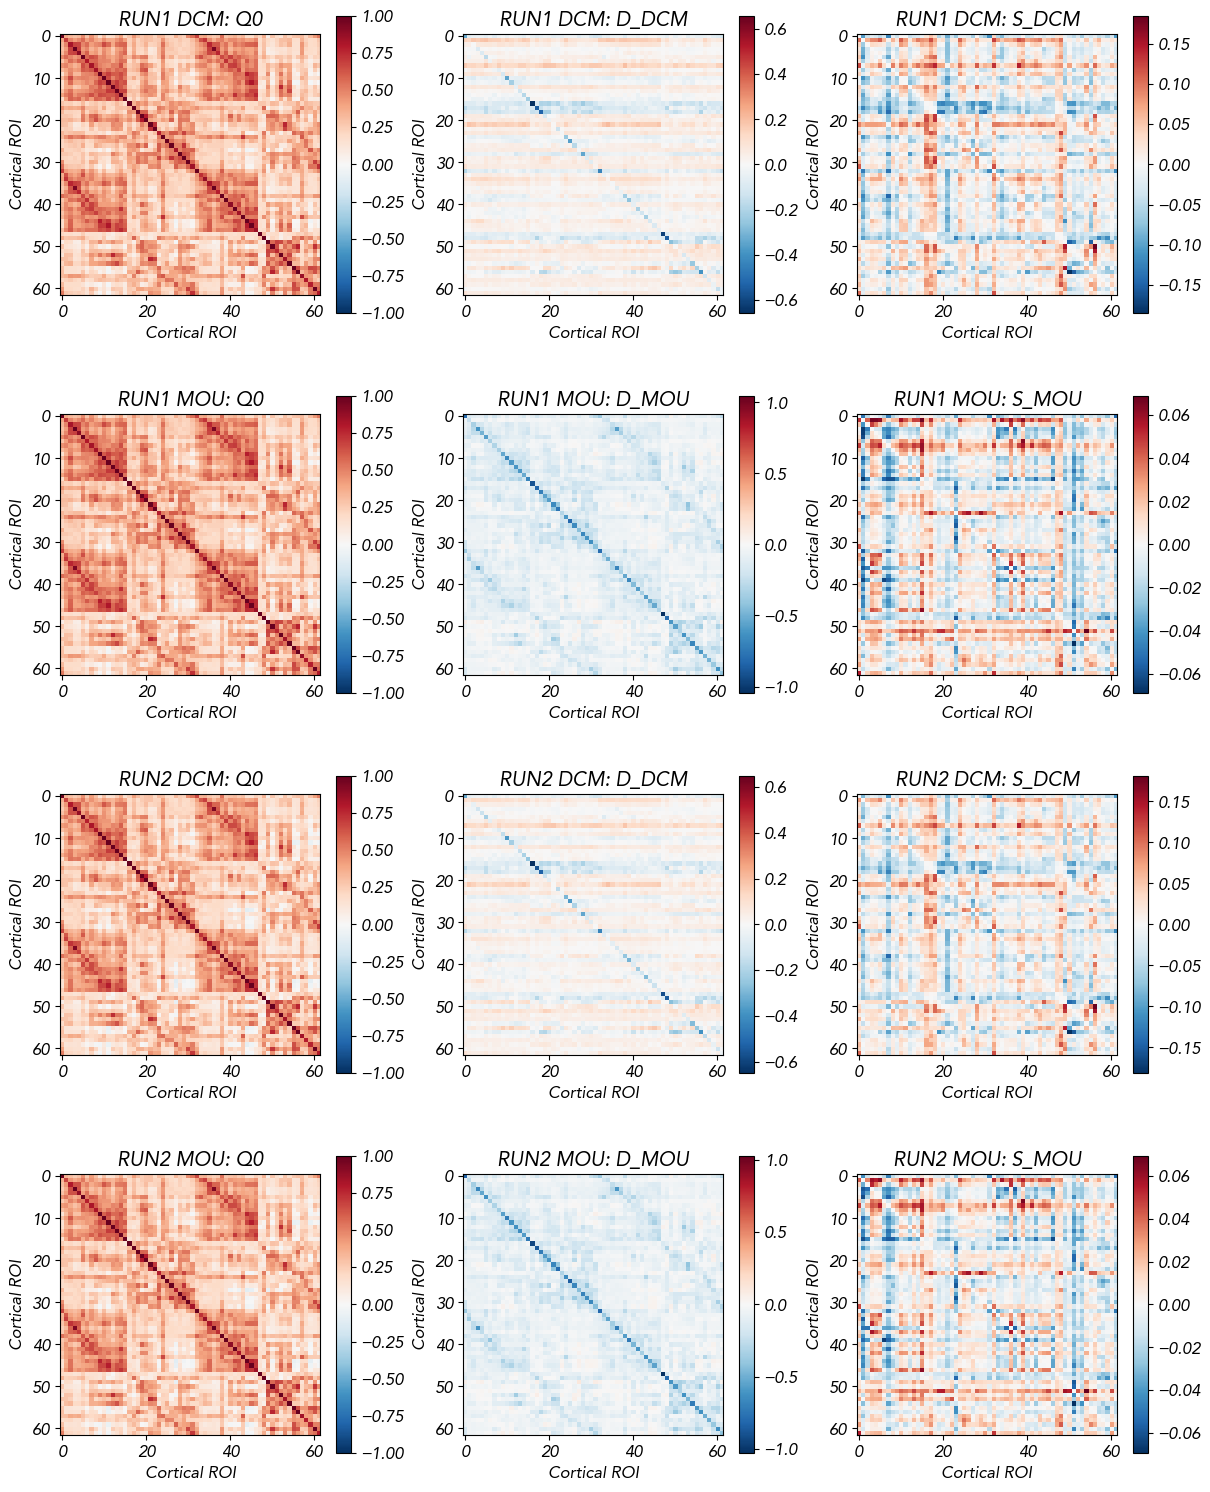

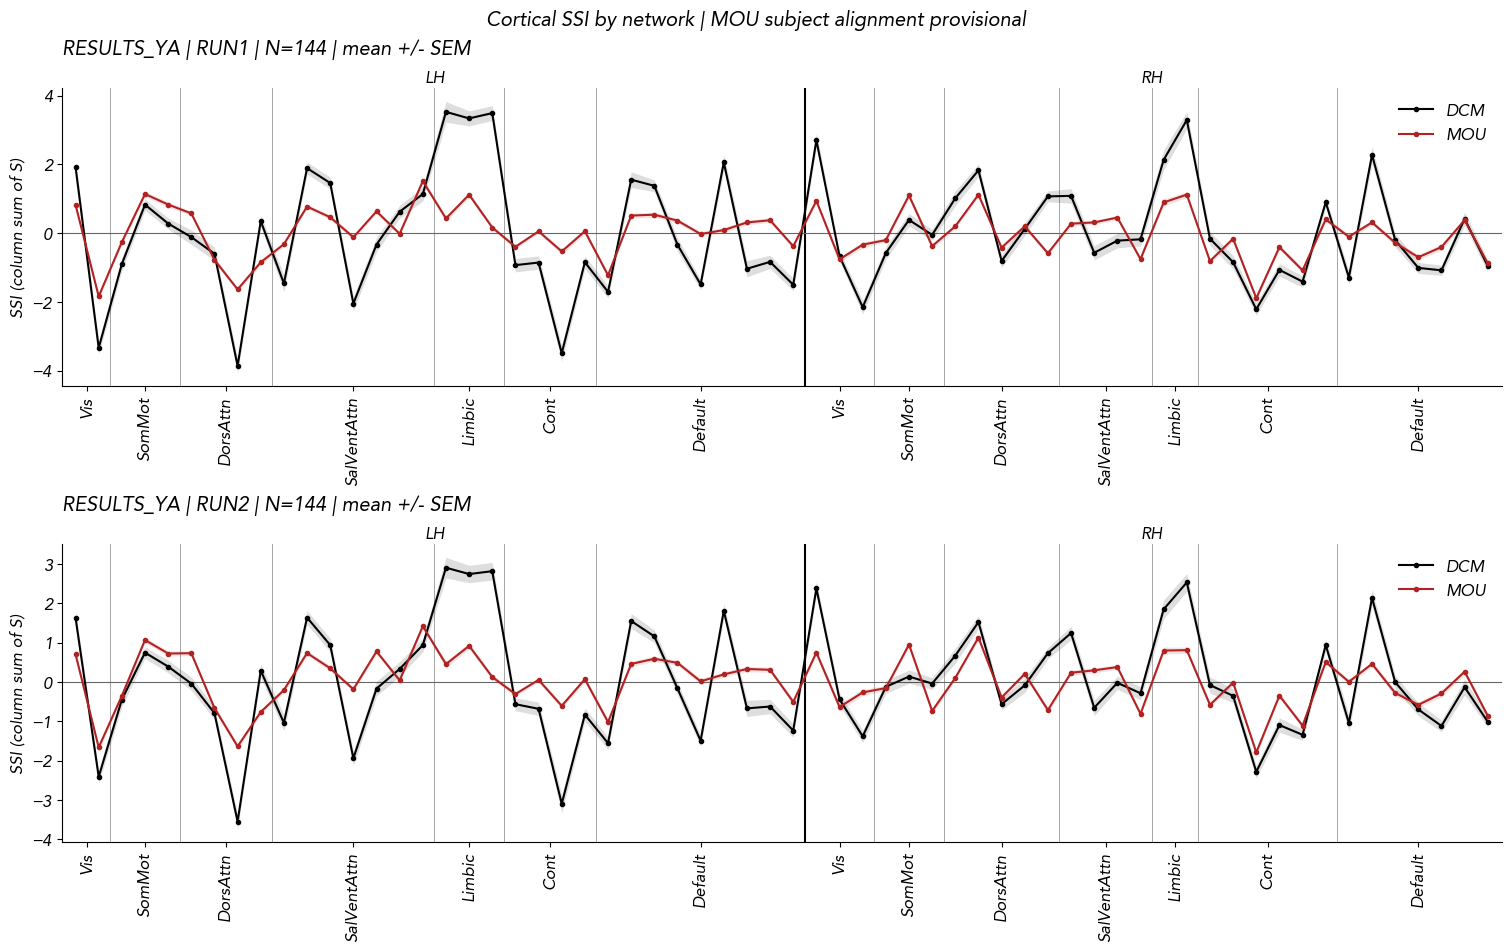

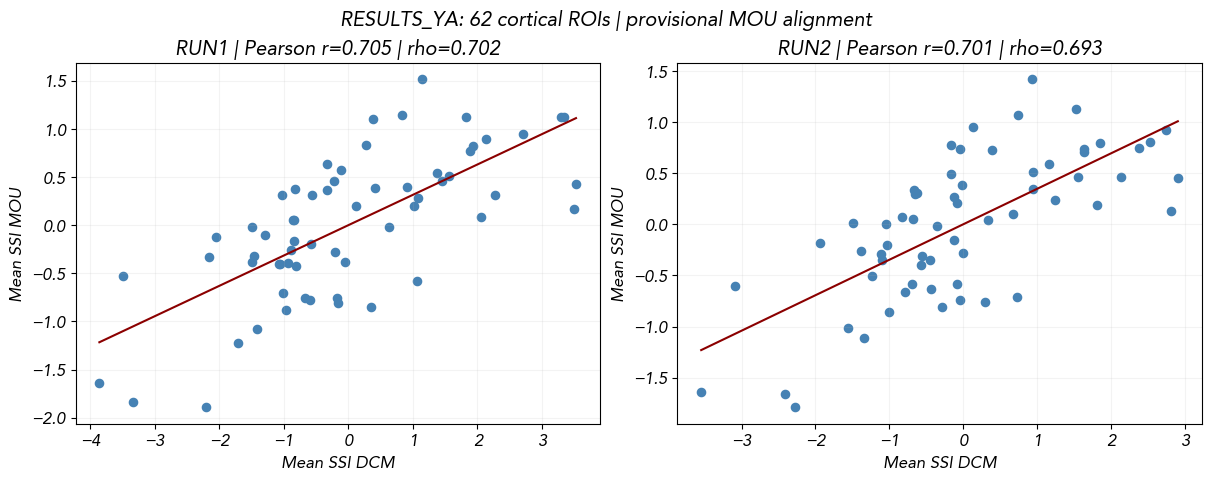

,cohort,run,subjects,ROIs,Pearson_r,Spearman_rho
0,RESULTS_YA,RUN1,144,62,0.704666,0.702198
1,RESULTS_YA,RUN2,144,62,0.700570,0.693183


In [4]:
plot_matrices(main,'RESULTS_YA')
plot_ssi(main,'RESULTS_YA')
main_correlations=plot_correlations(main,'RESULTS_YA')

## 2. DCM TR1 points16 e MOU RUN1 — coorte abbinata

Caricamento diretto di `A` dai file `sub-<ID>.mat_TR1_realData_var11_emo_points16.mat`. I file con A 74×74 vengono ridotti alle prime 62 regioni **prima di D**; quelli 62×62 sono usati integralmente. Si selezionano gli ID con dati BOLD validi e una posizione nel medesimo indice MOU ricostruito. Q0 e MOU RUN1 sono calcolate/selezionate per questa coorte, non si confronta il suo SSI con la media di un'altra coorte. Il report registra dimensioni originali e motivi di esclusione.

In [5]:
tr1_files={}
pattern=re.compile(r'^sub-(\d+)\.mat_TR1_realData_var11_emo_points16\.mat$')
for f in sorted(TR1_ROOT.glob('*TR1*.mat')):
    match=pattern.match(f.name)
    if match:
        sid=match.group(1)
        if sid in tr1_files:raise ValueError(f'Duplicate subject {sid}')
        tr1_files[sid]=f
assert tr1_files,'No TR1 points16 files found'
tr1_ids=[];tr1_audit=[]
for sid,f in sorted(tr1_files.items()):
    reasons=[]
    A=loadmat(f,variable_names=['A']).get('A')
    shape=None if A is None else A.shape
    if shape not in [(62,62),(74,74)]:reasons.append(f'unsupported A shape {shape}')
    elif not np.isfinite(A).all():reasons.append('nonfinite A')
    bfile=bold_path(sid,'RUN1')
    if not bfile.exists():reasons.append('missing BOLD RUN1')
    elif np.load(bfile,mmap_mode='r').shape!=(1200,112):reasons.append('BOLD shape RUN1')
    if sid not in mou_lookup:reasons.append('absent from reconstructed MOU index')
    tr1_audit.append({'subject_id':sid,'file':f.name,'original_A_shape':str(shape),
                      'included':not reasons,'reason':'; '.join(reasons)})
    if not reasons:tr1_ids.append(sid)
tr1={'RUN1':analyze(tr1_ids,'RUN1',tr1_files)}
pd.DataFrame(tr1_audit).to_csv(OUT/'TR1_points16_subject_audit.csv',index=False)
save_cohort(tr1,tr1_ids,'TR1_points16')
print('TR1 points16 files:',len(tr1_files),'included subjects:',len(tr1_ids))
display(pd.DataFrame(tr1_audit).query('not included'))


TR1 points16 files: 145 included subjects: 145


,subject_id,file,original_A_shape,included,reason


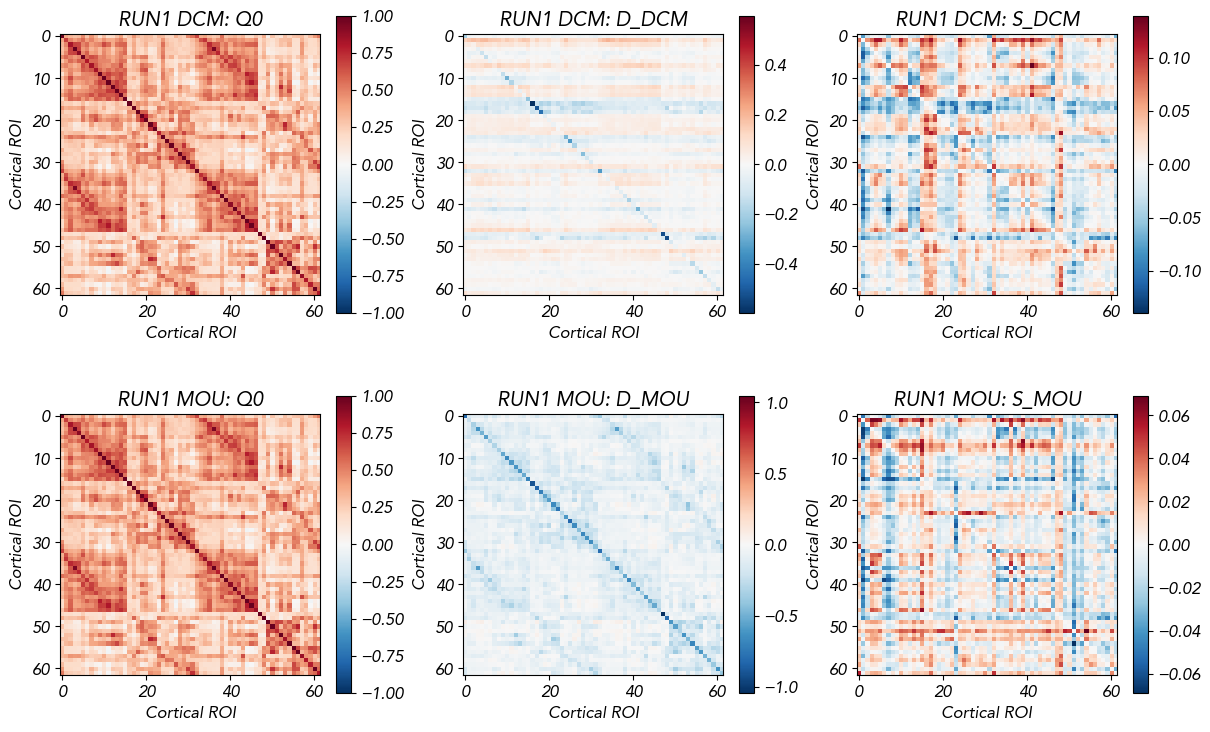

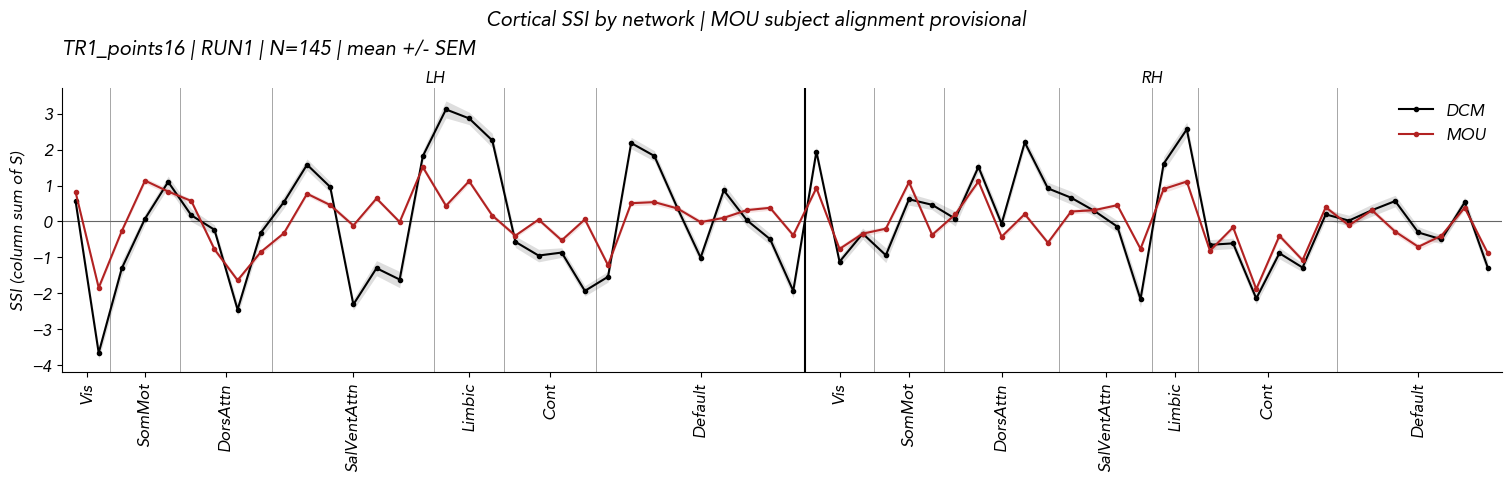

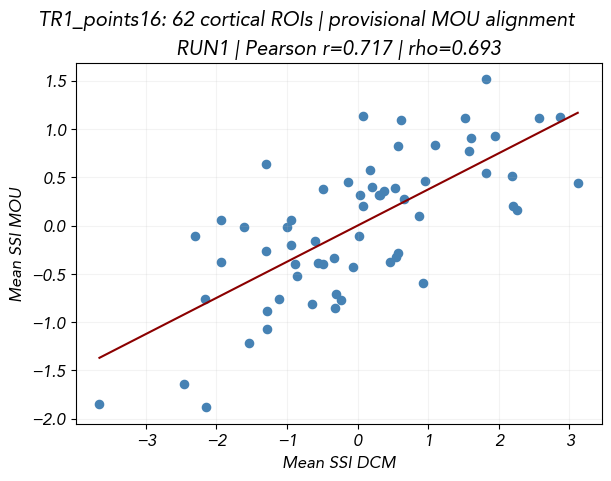

,cohort,run,subjects,ROIs,Pearson_r,Spearman_rho
0,TR1_points16,RUN1,145,62,0.71699,0.693334


Figures: /home/benedetta/Scripts/Insight_project/Figures/SSI_cortical_DCM_MOU
Data and audits: /home/benedetta/Scripts/Insight_project/numpy files/SSI_cortical_DCM_MOU


In [6]:
plot_matrices(tr1,'TR1_points16')
plot_ssi(tr1,'TR1_points16')
tr1_correlations=plot_correlations(tr1,'TR1_points16')
print('Figures:',FIGURES)
print('Data and audits:',OUT)